# CRISP-DM phase 2 : Data Understanding, D4 (Heart Failure Prediction)

Responsable : Aziz (maladies cardiaques)

**À surveiller :** Cible `DEATH_EVENT`, classes déséquilibrées (32 % / 68 %). La variable `time` (durée du suivi) est connue seulement après coup : risque de fuite d'information à discuter.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D4'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D4] lignes=299 pos=96 neg=203 | article: lignes=299 pos=96 neg=203 -> OK


('Heart Failure Prediction', (299, 13))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type (numérique, binaire, catégorielle), unité.

In [2]:
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
age,float64,47,40.0,95.0
anaemia,int64,2,0.0,1.0
creatinine_phosphokinase,int64,208,23.0,7861.0
diabetes,int64,2,0.0,1.0
ejection_fraction,int64,17,14.0,80.0
high_blood_pressure,int64,2,0.0,1.0
platelets,float64,176,25100.0,850000.0
serum_creatinine,float64,40,0.5,9.4
serum_sodium,int64,27,113.0,148.0
sex,int64,2,0.0,1.0


## 2. Variable cible

DEATH_EVENT
0    203
1     96
Name: count, dtype: int64 
 DEATH_EVENT
0    0.679
1    0.321
Name: count, dtype: float64


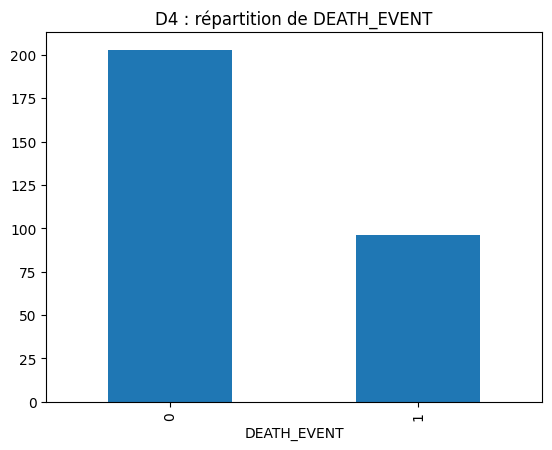

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}'); plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print(df.isna().sum()[df.isna().sum() > 0])
# zéros médicalement impossibles
for c in ['cholesterol', 'chol', 'resting bp s', 'trestbps', 'serum_sodium', 'platelets']:
    if c in df: print(c, '= 0 :', (df[c] == 0).sum())
for c, code in [('ca', 4), ('thal', 0)]:
    if c in df: print(c, '=', code, ':', (df[c] == code).sum())

Series([], dtype: int64)
serum_sodium = 0 : 0
platelets = 0 : 0


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes -> {len(df) - n_dup} lignes uniques')
df.drop_duplicates()[target].value_counts()

0 doublons sur 299 lignes -> 299 lignes uniques


DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.83,11.89,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.63,4.41,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0


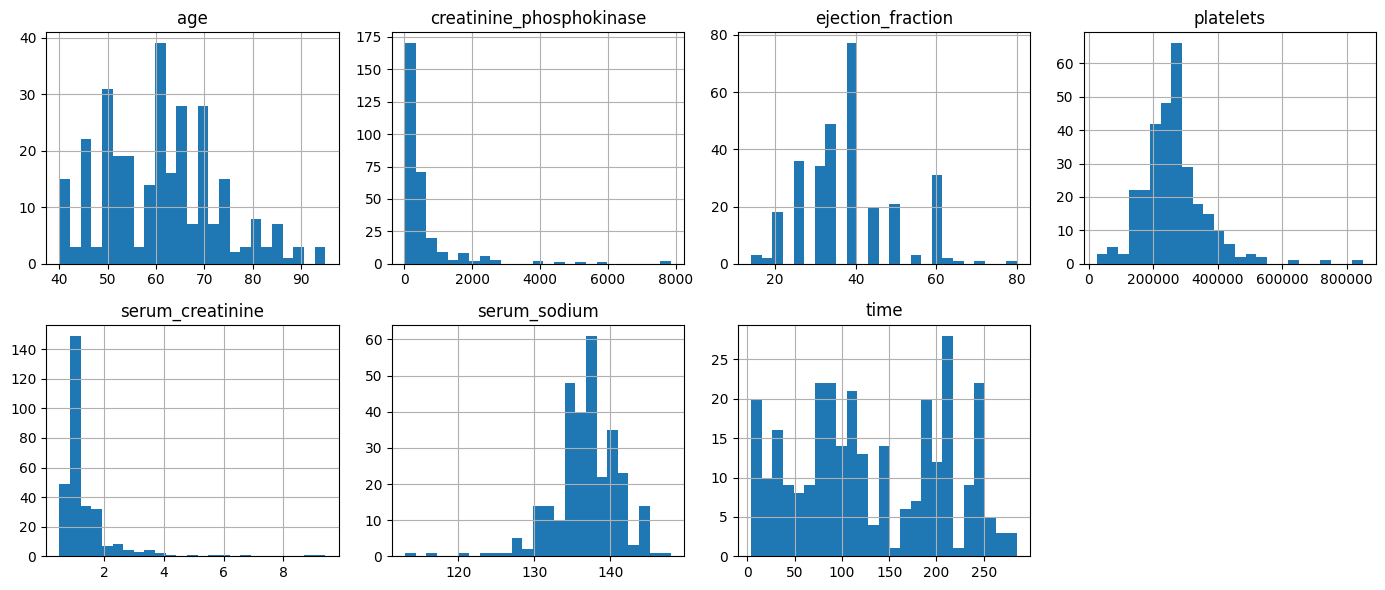

In [8]:
num = [c for c in df.columns if c != target and df[c].nunique() > 5]
df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4)); plt.tight_layout(); plt.show()

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
iqr = q3 - q1
((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)

creatinine_phosphokinase    29
serum_creatinine            29
platelets                   21
serum_sodium                 4
ejection_fraction            2
age                          0
time                         0
dtype: int64

## 7. Variables selon la classe

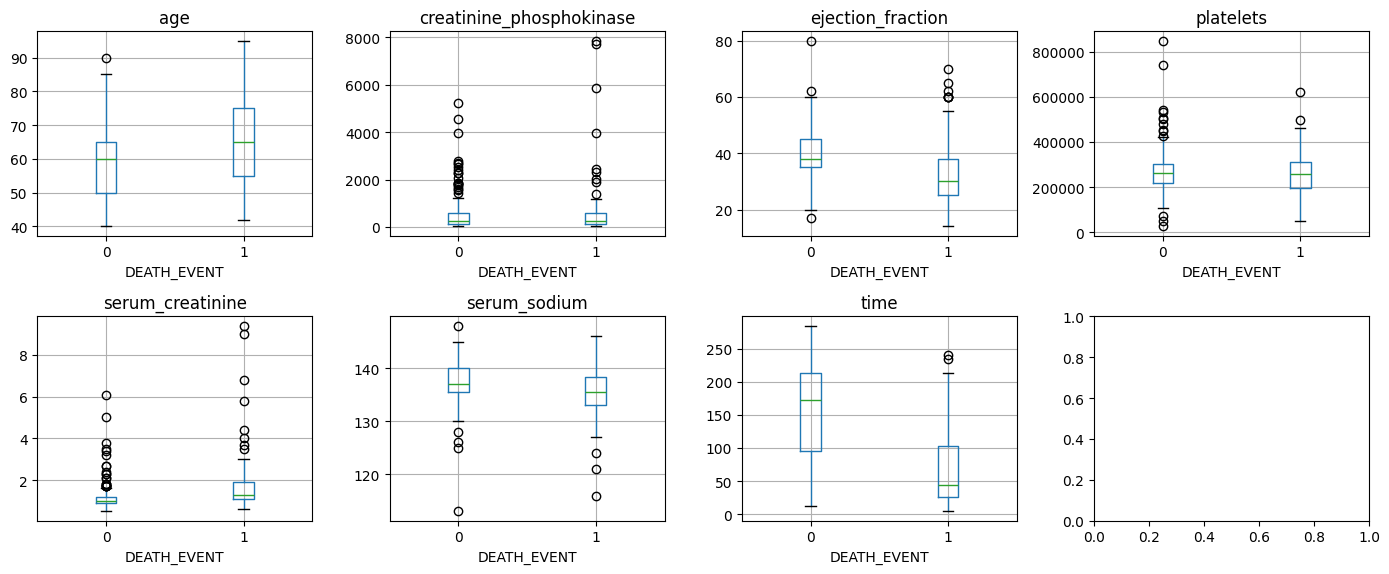

In [10]:
fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
for ax, c in zip(axes.flat, num):
    df.boxplot(column=c, by=target, ax=ax)
plt.suptitle(''); plt.tight_layout(); plt.show()

In [11]:
cat = [c for c in df.columns if c != target and df[c].nunique() <= 5]
for c in cat:
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

DEATH_EVENT     0     1
anaemia                
0            0.71  0.29
1            0.64  0.36 

DEATH_EVENT     0     1
diabetes               
0            0.68  0.32
1            0.68  0.32 

DEATH_EVENT             0     1
high_blood_pressure            
0                    0.71  0.29
1                    0.63  0.37 

DEATH_EVENT     0     1
sex                    
0            0.68  0.32
1            0.68  0.32 

DEATH_EVENT     0     1
smoking                
0            0.67  0.33
1            0.69  0.31 



## 8. Corrélations

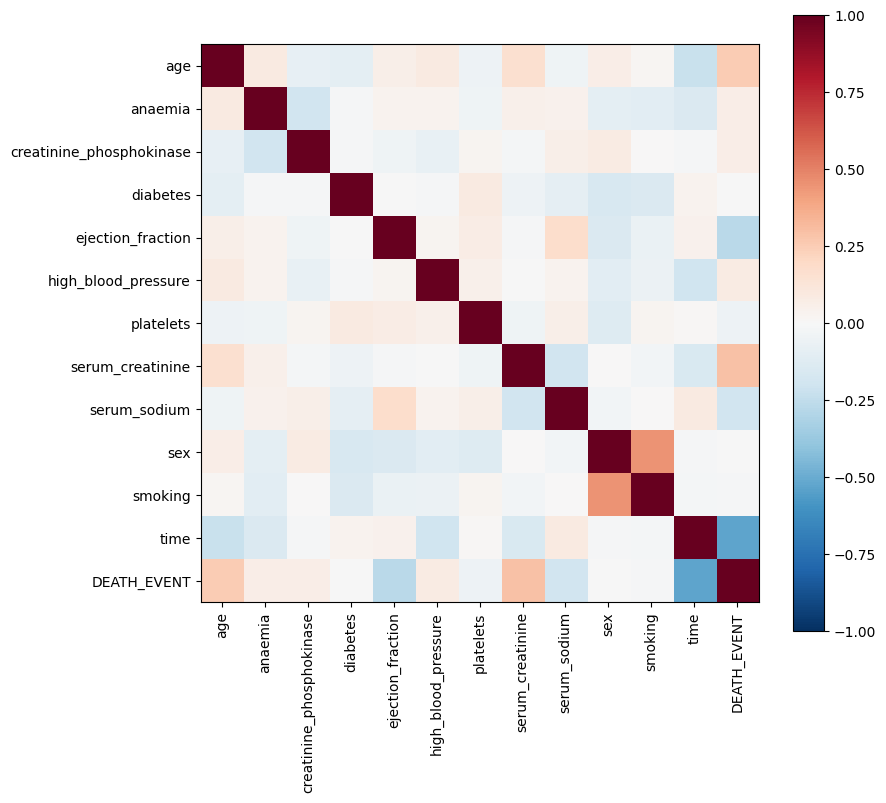

time                       -0.526964
serum_creatinine            0.294278
ejection_fraction          -0.268603
age                         0.253729
serum_sodium               -0.195204
high_blood_pressure         0.079351
anaemia                     0.066270
creatinine_phosphokinase    0.062728
platelets                  -0.049139
smoking                    -0.012623
sex                        -0.004316
diabetes                   -0.001943
Name: DEATH_EVENT, dtype: float64

In [12]:
corr = df.select_dtypes('number').corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
plt.colorbar(im); plt.show()
corr[target].drop(target).sort_values(key=abs, ascending=False)

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder :
- Valeurs manquantes / codées à traiter :
- Doublons : gardés (reproduction) + expérience `--dedup`
- Normalisation : StandardScaler dans le Pipeline (ajusté sur le train)
- Points pour la discussion critique :